# 03 · Full-period combinatorial structure, 2008–2024 (H1)

**Question.** Do tactics co-occur inside actions more or less often than the reference models expect, once each tactic's frequency and each action's number of tactics are held fixed?

**Estimands, per pair of tactics *h* and reference model**

* Observed co-occurrences $O_h$ (actions listing both tactics) and expected $E_h$ = mean over the 999 reference samples; reference SD.
* Effect $\theta_h=\log_2\big((O_h+0.5)/(E_h+0.5)\big)$; difference $O_h-E_h$; $z_h=(O_h-E_h)/\mathrm{sd}_h$; two-sided Monte Carlo $p$ and Benjamini–Hochberg $q$ over all 595 pairs. Pair-level $p$ values are descriptive; they are not a selection criterion.
* Global discrepancy (pilot statistic): $D=\sum_{h\in H}(O_h-E_h)^2/(E_h+1)$ over eligible pairs, compared with the same statistic computed on each reference sample against the mean of the other samples.

**Eligibility (frozen).** Both tactics appear in at least 50 main-sample actions over 2008–2024 and $E^{N1}_h\ge5$. The same set is used for every reference; a comparison additionally requires $E_h\ge5$ and a non-degenerate reference under the model being evaluated. All 595 pairs, including never-observed ones, are saved.

**Inputs.** `../results/aggregates/null_*.npz` (per-year replicate counts) from notebook 02; tactic dictionary and marginals from notebook 01.

In [1]:
import os
for k in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"]:
    os.environ.setdefault(k, "2")
import json, itertools
from pathlib import Path
from IPython.display import display
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, spearmanr

ROOT = Path(os.environ.get("PROTEST_ROOT", Path.cwd())).expanduser().resolve()
if not (ROOT / "config" / "analysis_config_v2.json").is_file():
    ROOT = ROOT.parent
if not (ROOT / "config" / "analysis_config_v2.json").is_file():
    raise FileNotFoundError("Open this notebook from the repository root or its notebooks folder, or set PROTEST_ROOT.")
CFG = json.loads((ROOT / "config" / "analysis_config_v2.json").read_text())
TAB = ROOT / "results" / "tables"; AGG = ROOT / "results" / "aggregates"
DIAG = ROOT / "results" / "diagnostics"
DIAG.mkdir(parents=True, exist_ok=True)
TAB.mkdir(parents=True, exist_ok=True)

def display_figure(fig, name):
    """Show and export the same diagnostic figure."""
    display(fig)
    fig.savefig(DIAG / f"{name}.pdf", bbox_inches="tight")
    plt.close(fig)


def display_and_save_table(df, name, index=False, float_format="%.4f"):
    display(df)
    df.to_csv(TAB / f"{name}.csv", index=index)
    df.to_latex(TAB / f"{name}.tex", index=index, escape=True, float_format=lambda x: float_format % x)
    return df
PAIRS = np.array(list(itertools.combinations(range(1, 36), 2)))
SPECS = ["N1", "N2", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]
dic = pd.read_csv(TAB / "tactic_dictionary.csv").set_index("code")
marg = pd.read_csv(TAB / "tactic_counts_by_year.csv").set_index("year")
marg.columns = marg.columns.astype(int)
total_marg = marg.sum()
YEARS = np.arange(2008, 2025)

## 1. Pair tables for every reference

In [2]:
def bh(p):
    o = np.argsort(p); s = p[o]
    q = np.minimum.accumulate((s * len(s) / np.arange(1, len(s) + 1))[::-1])[::-1]
    out = np.empty_like(p); out[o] = np.minimum(q, 1); return out

models = {}
for name in SPECS:
    z = np.load(AGG / f"null_{name}.npz")
    sims = z["counts"].sum(1).astype(float)          # 999 x 595, full period
    O = z["observed_year"].sum(0).astype(float)
    R = sims.shape[0]
    E = sims.mean(0); sd = sims.std(0, ddof=1)
    theta = np.log2((O + .5) / (E + .5))
    p = np.minimum(1, 2 * np.minimum((1 + (sims >= O).sum(0)) / (R + 1), (1 + (sims <= O).sum(0)) / (R + 1)))
    models[name] = dict(O=O, E=E, sd=sd, theta=theta, p=p, q=bh(p), sims=sims,
                        Oy=z["observed_year"].astype(float), Ey=z["counts"].mean(0), counts=z["counts"])
E_N1 = models["N1"]["E"]
elig = (total_marg.loc[PAIRS[:, 0]].to_numpy() >= 50) & (total_marg.loc[PAIRS[:, 1]].to_numpy() >= 50) & (E_N1 >= 5)
reason = np.where(total_marg.loc[PAIRS[:, 0]].to_numpy() < 50, "tactic_i_below_50",
         np.where(total_marg.loc[PAIRS[:, 1]].to_numpy() < 50, "tactic_j_below_50",
         np.where(E_N1 < 5, "E_N1_below_5", "eligible")))
elig_table = pd.DataFrame({"code_i": PAIRS[:, 0], "code_j": PAIRS[:, 1],
                           "label_i": dic.loc[PAIRS[:, 0], "label_en"].to_numpy(), "label_j": dic.loc[PAIRS[:, 1], "label_en"].to_numpy(),
                           "marginal_i": total_marg.loc[PAIRS[:, 0]].to_numpy(), "marginal_j": total_marg.loc[PAIRS[:, 1]].to_numpy(),
                           "E_N1": E_N1, "eligible": elig, "reason": reason})
display_and_save_table(elig_table, "eligibility_primary")
np.save(AGG / "eligible_primary.npy", elig)
print("eligible pairs:", int(elig.sum()), "of 595")
print(elig_table.reason.value_counts().to_dict())

eligible pairs: 291 of 595
{'eligible': 291, 'E_N1_below_5': 205, 'tactic_j_below_50': 66, 'tactic_i_below_50': 33}


,code_i,code_j,label_i,label_j,marginal_i,marginal_j,E_N1,eligible,reason
0,1,2,March,Static demonstration,6317,6597,1085.877878,True,eligible
1,1,3,March,Rally with speakers,6317,674,142.777778,True,eligible
2,1,4,March,Caravan,6317,521,85.723724,True,eligible
3,1,5,March,Petition or fund collection,6317,720,126.759760,True,eligible
4,1,6,March,Peaceful civil disobedience,6317,43,5.800801,False,tactic_j_below_50
...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,95,359,1.921922,False,E_N1_below_5
591,32,35,Clashes with counter-protesters,Hostage taking,95,5,0.016016,False,tactic_j_below_50
592,33,34,Attack on police or security forces,Attack on bystanders,2100,359,28.723724,True,eligible
593,33,35,Attack on police or security forces,Hostage taking,2100,5,0.376376,False,tactic_j_below_50


In [3]:
for name, m in models.items():
    t = pd.DataFrame({"code_i": PAIRS[:, 0], "code_j": PAIRS[:, 1],
                      "label_i": dic.loc[PAIRS[:, 0], "label_en"].to_numpy(), "label_j": dic.loc[PAIRS[:, 1], "label_en"].to_numpy(),
                      "family_i": dic.loc[PAIRS[:, 0], "family_label"].to_numpy(), "family_j": dic.loc[PAIRS[:, 1], "family_label"].to_numpy(),
                      "observed": m["O"].astype(int), "expected": m["E"], "sd_reference": m["sd"], "difference": m["O"] - m["E"],
                      "z": np.divide(m["O"] - m["E"], m["sd"], out=np.full(595, np.nan), where=m["sd"] > 0),
                      "log2_ratio": m["theta"], "p_mc_two_sided": m["p"], "q_bh_595": m["q"], "eligible_primary": elig,
                      "evaluable": elig & (m["E"] >= 5) & (m["sd"] > 0)})
    display_and_save_table(t, f"pairs_full_period_{name}")
    m["table"] = t
models["N2"]["table"].query("evaluable").sort_values("log2_ratio").head(8)[["label_i", "label_j", "observed", "expected", "log2_ratio", "q_bh_595"]]

,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,358,1085.877878,25.687405,-727.877878,-28.335983,-1.599481,0.002,0.006166,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,142.777778,10.325595,339.222222,32.852561,1.751714,0.002,0.006166,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,77,85.723724,8.091891,-8.723724,-1.078082,-0.153889,0.318,0.551633,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,312,126.759760,9.887156,185.240240,18.735442,1.296080,0.002,0.006166,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,1,5.800801,2.097178,-4.800801,-2.289172,-2.070573,0.028,0.069129,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,3,1.921922,1.351875,1.078078,0.797469,0.531203,0.604,0.914453,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.016016,0.125600,-0.016016,-0.127516,-0.045488,1.000,1.000000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,70,28.723724,5.086797,41.276276,8.114395,1.270483,0.002,0.006166,True,True
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,1,0.376376,0.570204,0.623624,1.093685,0.775340,0.672,0.980513,False,False


,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,358,603.436436,18.842766,-245.436436,-13.025500,-0.752424,0.002,0.00758,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,161.609610,10.472684,320.390390,30.592960,1.573559,0.002,0.00758,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,77,55.748749,6.404058,21.251251,3.318404,0.462375,0.002,0.00758,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,312,141.059059,10.351610,170.940941,16.513464,1.142452,0.002,0.00758,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,1,2.523524,1.438519,-1.523524,-1.059092,-1.011268,0.514,0.82434,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,3,3.633634,1.766395,-0.633634,-0.358716,-0.240056,1.000,1.00000,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.00000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,70,72.795796,6.147514,-2.795796,-0.454785,-0.056107,0.754,1.00000,True,True
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,1,0.534535,0.647609,0.465465,0.718745,0.535981,0.912,1.00000,False,False


,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.000000,True,False
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,452,160.877878,9.830176,291.122122,29.615148,1.487475,0.002,0.009370,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,72,56.698699,6.108923,15.301301,2.504746,0.341999,0.024,0.083509,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,310,146.837838,9.942003,163.162162,16.411398,1.075465,0.002,0.009370,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,1,2.473473,1.356735,-1.473473,-1.086044,-0.987187,0.464,0.917209,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,3,3.192192,1.659701,-0.192192,-0.115799,-0.077123,1.000,1.000000,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.000000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,56,68.108108,5.882136,-12.108108,-2.058454,-0.280128,0.046,0.143298,True,True
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,1,0.664665,0.696874,0.335335,0.481199,0.365048,1.000,1.000000,False,False


,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,447,695.577578,21.605818,-248.577578,-11.505122,-0.637360,0.002,0.007169,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,498,157.339339,10.308078,340.660661,33.047931,1.659137,0.002,0.007169,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,83,57.093093,6.541554,25.906907,3.960360,0.535880,0.004,0.013077,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,330,145.678679,10.175113,184.321321,18.114917,1.176917,0.002,0.007169,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,1,2.337337,1.392550,-1.337337,-0.960351,-0.919575,0.580,0.889433,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,4,3.402402,1.782298,0.597598,0.335296,0.205562,0.894,1.000000,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.000000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,78,78.055055,6.578642,-0.055055,-0.008369,-0.001011,1.000,1.000000,True,True
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,1,0.704705,0.742287,0.295295,0.397818,0.316283,1.000,1.000000,False,False


,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,358,766.105105,18.089401,-408.105105,-22.560455,-1.096510,0.002,0.007437,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,218.530531,11.119357,263.469469,23.694668,1.139397,0.002,0.007437,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,77,67.608609,6.385257,9.391391,1.470793,0.186359,0.168,0.350737,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,312,177.399399,10.065897,134.600601,13.371943,0.812795,0.002,0.007437,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,1,2.972973,1.469213,-1.972973,-1.342877,-1.211209,0.324,0.591350,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,3,3.414414,1.711224,-0.414414,-0.242174,-0.161442,1.000,1.000000,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.000000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,70,66.940941,5.904171,3.059059,0.518118,0.063999,0.640,0.989091,True,True
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,1,0.488488,0.601949,0.511512,0.849759,0.601666,0.868,1.000000,False,False


,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,sd_reference,difference,z,log2_ratio,p_mc_two_sided,q_bh_595,eligible_primary,evaluable
0,1,2,March,Static demonstration,A Peaceful I,A Peaceful I,116,497.837838,16.979645,-381.837838,-22.487975,-2.096794,0.002,0.01266,True,True
1,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,126,42.307307,5.537145,83.692693,15.114773,1.563208,0.002,0.01266,True,True
2,1,4,March,Caravan,A Peaceful I,A Peaceful I,23,26.575576,4.675871,-3.575576,-0.764686,-0.204331,0.476,1.00000,True,True
3,1,5,March,Petition or fund collection,A Peaceful I,A Peaceful I,115,42.456456,5.437922,72.543544,13.340306,1.426946,0.002,0.01266,True,True
4,1,6,March,Peaceful civil disobedience,A Peaceful I,A Peaceful I,0,2.005005,1.266564,-2.005005,-1.583028,-2.324813,0.204,0.61593,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
590,32,34,Clashes with counter-protesters,Attack on bystanders,F Violent,F Violent,0,0.130130,0.362417,-0.130130,-0.359062,-0.333722,1.000,1.00000,False,False
591,32,35,Clashes with counter-protesters,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.00000,False,False
592,33,34,Attack on police or security forces,Attack on bystanders,F Violent,F Violent,3,3.149149,1.713666,-0.149149,-0.087035,-0.060205,1.000,1.00000,True,False
593,33,35,Attack on police or security forces,Hostage taking,F Violent,F Violent,0,0.000000,0.000000,0.000000,NaN,0.000000,1.000,1.00000,False,False


,label_i,label_j,observed,expected,log2_ratio,q_bh_595
151,Petition or fund collection,Arson,0,24.843844,-5.663563,0.00758
113,Caravan,Building occupation,0,17.446446,-5.165626,0.00758
82,Rally with speakers,Building occupation,1,52.450450,-5.141609,0.00758
407,Artistic performance (artists),Building occupation,0,16.037037,-5.047629,0.00758
415,Artistic performance (artists),Arson,0,14.425425,-4.899700,0.00758
153,Petition or fund collection,Looting,0,10.487487,-4.457790,0.00758
452,Strike or stoppage,Looting,1,32.278278,-4.449706,0.00758
425,Symbolic action,Building occupation,3,72.046046,-4.373470,0.00758


## 2. Global discrepancy and the share of pairs that depart from the reference

In [4]:
def global_test(m, mask):
    mu = m["E"][mask]; O = m["O"][mask]; S = m["sims"][:, mask]; R = S.shape[0]
    D = float(np.sum((O - mu) ** 2 / (mu + 1)))
    loo = (S.sum(0) - S) / (R - 1)
    Ds = np.sum((S - loo) ** 2 / (loo + 1), axis=1)
    return D, Ds

rows = []
for name, m in models.items():
    mask = elig & (m["E"] >= 5) & (m["sd"] > 0)
    D, Ds = global_test(m, mask)
    th = m["theta"][mask]; q = m["q"][mask]
    rows.append({"reference": name, "evaluable_pairs": int(mask.sum()), "global_discrepancy": D, "reference_mean": Ds.mean(),
                 "reference_p95": np.quantile(Ds, .95), "excess_ratio": D / Ds.mean(), "p_mc": (1 + (Ds >= D).sum()) / (len(Ds) + 1),
                 "excess_q05": int(((th > 0) & (q < .05)).sum()), "deficit_q05": int(((th < 0) & (q < .05)).sum()),
                 "strong_excess": int((th >= np.log2(1.5)).sum()), "strong_deficit": int((th <= -np.log2(1.5)).sum()),
                 "never_observed": int((m["O"][mask] == 0).sum()), "median_abs_log2": float(np.median(np.abs(th)))})
glob = display_and_save_table(pd.DataFrame(rows), "global_structure_tests")
glob.round(3)

,reference,evaluable_pairs,global_discrepancy,reference_mean,reference_p95,excess_ratio,p_mc,excess_q05,deficit_q05,strong_excess,strong_deficit,never_observed,median_abs_log2
0,N1,291,20775.270006,221.955444,253.667457,93.601083,0.001,68,134,65,153,24,1.122288
1,N2,274,9062.266262,182.280676,210.685342,49.716001,0.001,57,119,36,136,17,0.871389
2,N2_clean,209,5299.810128,142.916461,167.523333,37.083273,0.001,39,97,29,119,20,1.205892
3,N2_allmedia,280,10709.355010,192.283858,221.456326,55.695549,0.001,56,125,42,139,17,0.933584
4,N2_order,272,6843.251921,177.042663,203.543261,38.653124,0.001,58,117,34,129,16,0.801328
5,N1_k2,142,5221.897344,101.895109,124.091478,51.247772,0.001,26,58,26,73,21,1.224096


,reference,evaluable_pairs,global_discrepancy,reference_mean,reference_p95,excess_ratio,p_mc,excess_q05,deficit_q05,strong_excess,strong_deficit,never_observed,median_abs_log2
0,N1,291,20775.270,221.955,253.667,93.601,0.001,68,134,65,153,24,1.122
1,N2,274,9062.266,182.281,210.685,49.716,0.001,57,119,36,136,17,0.871
2,N2_clean,209,5299.810,142.916,167.523,37.083,0.001,39,97,29,119,20,1.206
3,N2_allmedia,280,10709.355,192.284,221.456,55.696,0.001,56,125,42,139,17,0.934
4,N2_order,272,6843.252,177.043,203.543,38.653,0.001,58,117,34,129,16,0.801
5,N1_k2,142,5221.897,101.895,124.091,51.248,0.001,26,58,26,73,21,1.224


## 3. Codebook families: a compact reading of the structure

Summing observed and expected counts over all pairs that link two codebook families gives a 6 × 6 table of family-level ratios. Sums are taken over all 595 pairs (no eligibility needed), so rare tactics contribute in proportion to their counts. Within-family excess is partly expected from how the codebook groups similar forms; the cross-family cells are the informative part.

In [5]:
fams = list(dict.fromkeys(dic.family_label))
fi = dic.loc[PAIRS[:, 0], "family_label"].to_numpy(); fj = dic.loc[PAIRS[:, 1], "family_label"].to_numpy()
fam_rows = []
for name in ["N1", "N2", "N2_clean"]:
    m = models[name]
    for a_i, A in enumerate(fams):
        for B in fams[a_i:]:
            sel = ((fi == A) & (fj == B)) | ((fi == B) & (fj == A))
            if not sel.any():
                continue
            O = m["O"][sel].sum(); E = m["E"][sel].sum(); S = m["sims"][:, sel].sum(1)
            fam_rows.append({"reference": name, "family_a": A, "family_b": B, "pairs": int(sel.sum()), "observed": int(O), "expected": E,
                             "log2_ratio": np.log2((O + .5) / (E + .5)), "z": (O - E) / S.std(ddof=1) if S.std() > 0 else np.nan,
                             "p_mc": min(1, 2 * min((1 + (S >= O).sum()) / (len(S) + 1), (1 + (S <= O).sum()) / (len(S) + 1)))})
fam_tab = display_and_save_table(pd.DataFrame(fam_rows), "family_structure")
fam_tab[fam_tab.reference == "N2"].pivot(index="family_a", columns="family_b", values="log2_ratio").reindex(index=fams, columns=fams).round(2)

,reference,family_a,family_b,pairs,observed,expected,log2_ratio,z,p_mc
0,N1,A Peaceful I,A Peaceful I,15,1691,1851.641642,-0.130891,-4.666721,0.002
1,N1,A Peaceful I,B Peaceful II,48,6697,3639.900901,0.879525,65.195462,0.002
2,N1,A Peaceful I,C Artistic,18,1443,847.555556,0.767340,23.812078,0.002
3,N1,A Peaceful I,D Disruptive,42,3562,5672.263263,-0.671162,-39.585330,0.002
4,N1,A Peaceful I,E Self-destructive,12,75,212.563564,-1.496735,-10.451511,0.002
...,...,...,...,...,...,...,...,...,...
58,N2_clean,D Disruptive,E Self-destructive,14,94,100.467467,-0.095504,-0.736372,0.498
59,N2_clean,D Disruptive,F Violent,63,2455,2600.376376,-0.082981,-4.293252,0.002
60,N2_clean,E Self-destructive,E Self-destructive,1,7,1.258258,2.092744,5.397479,0.002
61,N2_clean,E Self-destructive,F Violent,18,15,81.250250,-2.398955,-7.779384,0.002


family_b,A Peaceful I,B Peaceful II,C Artistic,D Disruptive,E Self-destructive,F Violent
family_a,,,,,,
A Peaceful I,0.27,0.56,0.62,0.01,-0.74,-0.10
B Peaceful II,NaN,0.02,0.01,-0.92,-1.37,-0.45
C Artistic,NaN,NaN,0.64,-1.40,-1.56,-1.31
D Disruptive,NaN,NaN,NaN,-0.24,-0.12,-0.04
E Self-destructive,NaN,NaN,NaN,NaN,2.19,-2.55
F Violent,NaN,NaN,NaN,NaN,NaN,0.47


## 4. Pair matrix (inspection plot; the publication figure is drawn in notebook 07)

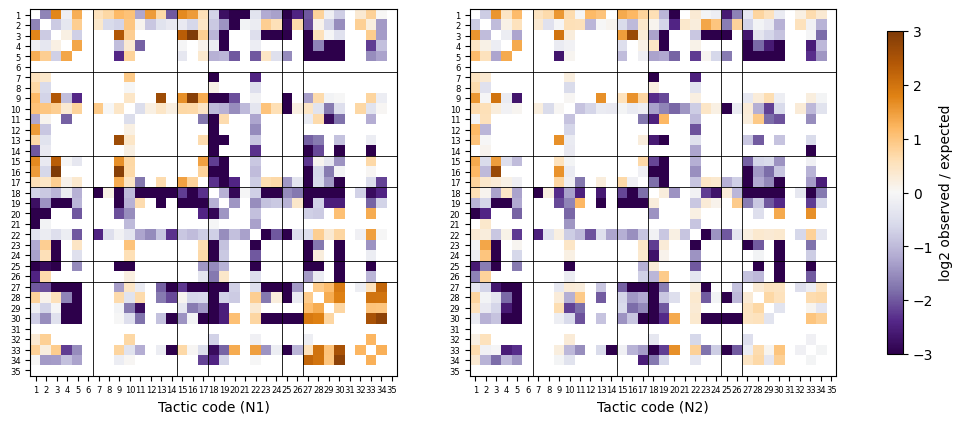

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, name in zip(axes, ["N1", "N2"]):
    m = models[name]; mask = elig & (m["E"] >= 5) & (m["sd"] > 0)
    M = np.full((35, 35), np.nan)
    for hh, (i, j) in enumerate(PAIRS):
        if mask[hh]:
            M[i - 1, j - 1] = M[j - 1, i - 1] = m["theta"][hh]
    im = ax.imshow(M, cmap="PuOr_r", vmin=-3, vmax=3)
    bounds = [6, 14, 17, 24, 26]
    for b in bounds:
        ax.axhline(b - .5, color="k", lw=.6); ax.axvline(b - .5, color="k", lw=.6)
    ax.set_xticks(range(35), range(1, 36), fontsize=6); ax.set_yticks(range(35), range(1, 36), fontsize=6)
    ax.set_xlabel(f"Tactic code ({name})")
fig.colorbar(im, ax=axes, shrink=.7, label="log2 observed / expected")
display_figure(fig, "full_period_pair_structure")

## 5. How similar are the two main references?

In [7]:
rows = []
for other in ["N2", "N2_clean", "N2_allmedia", "N2_order", "N1_k2"]:
    a, b = models["N1"], models[other]
    mask = elig & (a["E"] >= 5) & (b["E"] >= 5) & (a["sd"] > 0) & (b["sd"] > 0)
    rows.append({"reference": other, "pairs": int(mask.sum()), "pearson_vs_N1": pearsonr(a["theta"][mask], b["theta"][mask])[0],
                 "spearman_vs_N1": spearmanr(a["theta"][mask], b["theta"][mask])[0],
                 "sign_agreement_vs_N1": float((np.sign(a["theta"][mask]) == np.sign(b["theta"][mask])).mean()),
                 "median_abs_log2_N1": float(np.median(np.abs(a["theta"][mask]))), "median_abs_log2_other": float(np.median(np.abs(b["theta"][mask])))})
display_and_save_table(pd.DataFrame(rows), "reference_agreement_full_period").round(3)

,reference,pairs,pearson_vs_N1,spearman_vs_N1,sign_agreement_vs_N1,median_abs_log2_N1,median_abs_log2_other
0,N2,274,0.928142,0.905616,0.835766,1.051028,0.871389
1,N2_clean,209,0.896989,0.892766,0.851675,1.321107,1.205892
2,N2_allmedia,280,0.922206,0.898507,0.835714,1.070420,0.933584
3,N2_order,272,0.924353,0.898387,0.834559,1.033846,0.801328
4,N1_k2,142,0.611331,0.634381,0.760563,0.859877,1.224096


,reference,pairs,pearson_vs_N1,spearman_vs_N1,sign_agreement_vs_N1,median_abs_log2_N1,median_abs_log2_other
0,N2,274,0.928,0.906,0.836,1.051,0.871
1,N2_clean,209,0.897,0.893,0.852,1.321,1.206
2,N2_allmedia,280,0.922,0.899,0.836,1.070,0.934
3,N2_order,272,0.924,0.898,0.835,1.034,0.801
4,N1_k2,142,0.611,0.634,0.761,0.860,1.224


## 6. Largest departures (illustration only)

Listed: the ten largest positive and ten largest negative effects among evaluable pairs under N2 with $q<0.05$. They illustrate the structure; the quantitative results rest on all evaluable pairs.

In [8]:
t = models["N2"]["table"].query("evaluable and q_bh_595 < 0.05")
ill = pd.concat([t.nlargest(10, "log2_ratio"), t.nsmallest(10, "log2_ratio")])[
    ["code_i", "code_j", "label_i", "label_j", "family_i", "family_j", "observed", "expected", "log2_ratio", "q_bh_595"]]
ill.insert(0, "selection", ["largest_excess"] * 10 + ["largest_deficit"] * 10)
display_and_save_table(ill, "illustrative_pairs_N2")
ill.round(3)

,selection,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,log2_ratio,q_bh_595
79,largest_excess,3,16,Rally with speakers,Artistic performance (artists),A Peaceful I,C Artistic,85,12.812813,2.683109,0.00758
72,largest_excess,3,9,Rally with speakers,Commemoration,A Peaceful I,B Peaceful II,81,20.093093,1.984640,0.00758
487,largest_excess,20,33,Land occupation,Attack on police or security forces,D Disruptive,F Violent,43,13.455455,1.640186,0.00758
247,largest_excess,9,13,Commemoration,Vigil,B Peaceful II,B Peaceful II,38,11.930931,1.630924,0.00758
250,largest_excess,9,16,Commemoration,Artistic performance (artists),B Peaceful II,C Artistic,47,15.197197,1.597421,0.00758
1,largest_excess,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,161.609610,1.573559,0.00758
7,largest_excess,1,9,March,Commemoration,A Peaceful I,B Peaceful II,259,87.867868,1.554141,0.00758
78,largest_excess,3,15,Rally with speakers,Artistic performance (participants),A Peaceful I,C Artistic,44,15.301301,1.493762,0.00758
54,largest_excess,2,23,Static demonstration,Interrupting authorities,A Peaceful I,D Disruptive,87,32.643644,1.400551,0.00758
13,largest_excess,1,15,March,Artistic performance (participants),A Peaceful I,C Artistic,261,101.695696,1.355477,0.00758


,selection,code_i,code_j,label_i,label_j,family_i,family_j,observed,expected,log2_ratio,q_bh_595
79,largest_excess,3,16,Rally with speakers,Artistic performance (artists),A Peaceful I,C Artistic,85,12.813,2.683,0.008
72,largest_excess,3,9,Rally with speakers,Commemoration,A Peaceful I,B Peaceful II,81,20.093,1.985,0.008
487,largest_excess,20,33,Land occupation,Attack on police or security forces,D Disruptive,F Violent,43,13.455,1.640,0.008
247,largest_excess,9,13,Commemoration,Vigil,B Peaceful II,B Peaceful II,38,11.931,1.631,0.008
250,largest_excess,9,16,Commemoration,Artistic performance (artists),B Peaceful II,C Artistic,47,15.197,1.597,0.008
1,largest_excess,1,3,March,Rally with speakers,A Peaceful I,A Peaceful I,482,161.610,1.574,0.008
7,largest_excess,1,9,March,Commemoration,A Peaceful I,B Peaceful II,259,87.868,1.554,0.008
78,largest_excess,3,15,Rally with speakers,Artistic performance (participants),A Peaceful I,C Artistic,44,15.301,1.494,0.008
54,largest_excess,2,23,Static demonstration,Interrupting authorities,A Peaceful I,D Disruptive,87,32.644,1.401,0.008
13,largest_excess,1,15,March,Artistic performance (participants),A Peaceful I,C Artistic,261,101.696,1.355,0.008
